      price  area  bedrooms  ...  parking  prefarea furnishingstatus
0  13300000  7420         4  ...        2       yes        furnished
1  12250000  8960         4  ...        3        no        furnished
2  12250000  9960         3  ...        2       yes   semi-furnished
3  12215000  7500         4  ...        3       yes        furnished
4  11410000  7420         4  ...        2        no        furnished

[5 rows x 13 columns]
      price  ...  furnishingstatus_unfurnished
0  13300000  ...                         False
1  12250000  ...                         False
2  12250000  ...                         False
3  12215000  ...                         False
4  11410000  ...                         False

[5 rows x 14 columns]
Original Features : 13
Polynomial Features : 2379
LINEAR REGRESSION
Training R2 : 0.994
Testing R2 : -2874.767
RIDGE
Training R2 : 0.9637
Testing R2 : 0.2892
               Model  Train R2      Test R2
0  Linear Regression  0.994023 -2874.766987
1           

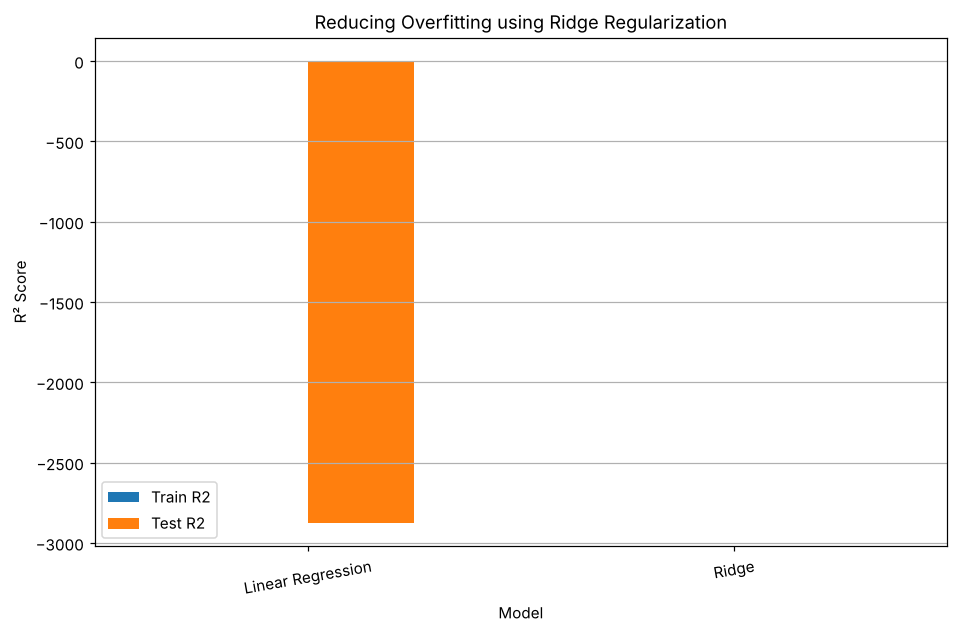

               Model  Train R2      Test R2  Difference
0  Linear Regression  0.994023 -2874.766987  2875.76101
1              Ridge  0.963736     0.289156     0.67458


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import r2_score

df = pd.read_csv("Housing.csv")

df.head()

df = pd.get_dummies(df, drop_first=True)

df.head()

X = df.drop("price", axis=1)
y = df["price"]

X_train,X_test,y_train,y_test = train_test_split(
X,
y,
test_size=0.2,
random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

poly = PolynomialFeatures(
    degree=4,
    include_bias=False
)

X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)

print("Original Features :", X_train.shape[1])
print("Polynomial Features :", X_train_poly.shape[1])

linear = LinearRegression()

linear.fit(X_train_poly, y_train)

train_pred = linear.predict(X_train_poly)
test_pred = linear.predict(X_test_poly)

train_r2 = r2_score(y_train, train_pred)
test_r2 = r2_score(y_test, test_pred)

print("LINEAR REGRESSION")
print("Training R2 :", round(train_r2,4))
print("Testing R2 :", round(test_r2,4))

ridge = Ridge(alpha=100)

ridge.fit(X_train_poly, y_train)

train_pred = ridge.predict(X_train_poly)
test_pred = ridge.predict(X_test_poly)

ridge_train = r2_score(y_train, train_pred)
ridge_test = r2_score(y_test, test_pred)

print("RIDGE")
print("Training R2 :", round(ridge_train,4))
print("Testing R2 :", round(ridge_test,4))

comparison = pd.DataFrame({

    "Model":[
        "Linear Regression",
        "Ridge"
    ],

    "Train R2":[
        train_r2,
        ridge_train
    ],

    "Test R2":[
        test_r2,
        ridge_test
    ]
})

print(comparison)

comparison.plot(
    x="Model",
    y=["Train R2", "Test R2"],
    kind="bar",
    figsize=(10,6)
)

plt.title("Reducing Overfitting using Ridge Regularization")
plt.ylabel("R² Score")
plt.xticks(rotation=10)
plt.grid(axis="y")
plt.show()

comparison["Difference"] = comparison["Train R2"] - comparison["Test R2"]

print(comparison)
